# Validate the market core

The market without the Studio: only `core/` (`core.config`, `core.market`,
`core.grid`), the same
calls a notebook or an RL trainer makes. Every step is shown as plain tables, so
when something looks wrong it is the core, not the UI.

1. **Scenario**: network, day, participants
2. **Inputs**: what each participant generates and needs per step
3. **One step**: orders, then each clearing stage, then settlement
4. **The whole day**: one row per step
5. **Checks**: rules every step must keep (a failing check names the step)
6. **Experiments**: change one setting, compare the day

Run top to bottom. Change the scenario in section 1 and run again.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from core.config import placement
from core.config.scenario import Scenario
from core.market.clearing import DSO_ID
from core.market.lem import LocalEnergyMarket, StepRecord

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

## 1. Scenario

Everything the market is built from. The defaults are `Scenario()`'s; change
any field here. `placement.place_all(scenario, "prosumers")` puts one
participant on every bus with a load **and** a generator, `"loads"` on every
bus with a load.

The scenario is saved to `notebooks/scenarios/validate_market.json`, the
format the Studio keeps its scenario in. In the Studio, click **Scenario: …**
in the header and open `validate_market.json` to play the same scenario on
the Step page; `tests/test_studio_matches_core.py` checks both give the same day.

In [ ]:
from core.config import store
from core.config.scenario import BatterySetup, ParticipantSetup, Scenario

net = "LV1.101 "
scenario = Scenario(name="validate_market")
scenario.market.partner_preference = True
scenario.participants = [
    ParticipantSetup("P1", net + "Bus 7", [net + "Load 9", net + "SGen 1"], BatterySetup(10)),
    ParticipantSetup("P2", net + "Bus 8", [net + "Load 2", net + "SGen 4"]),
    ParticipantSetup("P3", net + "Bus 1", [net + "Load 8"]),
    ParticipantSetup("P4", net + "Bus 5", [net + "Load 13"]),
    ParticipantSetup("P5", net + "Bus 12", [net + "Load 10"], BatterySetup(10)),
]

# The same scenario for the Studio (header: Scenario: … > Open). Read back,
# so the notebook runs the file.
SCENARIO_FILE = ROOT / "notebooks" / "scenarios" / "validate_market.json"
store.save(scenario, SCENARIO_FILE)
scenario = store.load(SCENARIO_FILE)
print(f"Saved to {SCENARIO_FILE.relative_to(ROOT)}")

Saved to notebooks\scenarios\validate_market.json


In [3]:
def participants_table(scenario: Scenario) -> pd.DataFrame:
    """One row per participant: bus, what it took over, its battery."""
    kinds = {
        e.id: e.element_type
        for elements in placement.elements_by_bus(scenario).values()
        for e in elements
    }
    rows = []
    for p in scenario.participants:
        b = p.battery
        rows.append(
            {
                "id": p.id,
                "bus": p.bus,
                "loads": sum(kinds.get(e) == "load" for e in p.owns),
                "generators": sum(kinds.get(e) == "sgen" for e in p.owns),
                "storage": sum(kinds.get(e) == "storage" for e in p.owns),
                "battery_kwh": b.capacity_kwh if b else 0.0,
                "soc_start": b.initial_soc if b else None,
                "soc_window": f"{b.min_soc}-{b.max_soc}" if b else None,
            }
        )
    return pd.DataFrame(rows).set_index("id")


participants_table(scenario)

,bus,loads,generators,storage,battery_kwh,soc_start,soc_window
id,,,,,,,
P1,LV1.101 Bus 7,1,1,0,10.0,0.5,0.1-0.9
P2,LV1.101 Bus 8,1,1,0,0.0,NaN,None
P3,LV1.101 Bus 1,1,0,0,0.0,NaN,None
P4,LV1.101 Bus 5,1,0,0,0.0,NaN,None
P5,LV1.101 Bus 12,1,0,0,10.0,0.5,0.1-0.9


## 2. Inputs per step

Generation and demand in kWh per step, read from the SimBench profiles of the
elements each participant took over. **Net = generation − demand**: positive
means the participant has energy to sell (or to put in its battery), negative
means it needs energy.

A peer-to-peer trade needs a seller **and** a buyer in the same step. The last
table counts them before any battery is used.

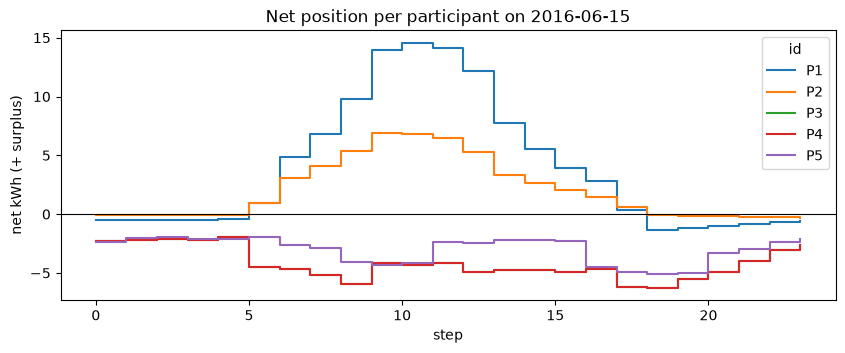

step,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
with surplus,0.000,0.000,0.000,0.000,0.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.00,2.000,0.000,0.000,0.000,0.000,0.000,0.000
with deficit,5.000,5.000,5.000,5.000,5.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.00,3.000,5.000,5.000,5.000,5.000,5.000,5.000
total net kWh,-7.559,-6.949,-6.772,-7.013,-6.477,-9.062,-4.054,-2.294,-0.855,8.288,8.529,9.955,5.168,-0.616,-3.554,-6.157,-9.57,-16.384,-19.024,-17.355,-14.308,-12.067,-9.381,-8.362


In [4]:
def inputs_table(lem: LocalEnergyMarket) -> pd.DataFrame:
    """Generation, demand and net per step and participant (kWh)."""
    rows = []
    for t in range(lem.n_steps):
        for pid, p in lem.participants.items():
            g, d = p.generation_kwh[t], p.demand_kwh[t]
            rows.append({"step": t, "id": pid, "gen": g, "dem": d, "net": p.net_kwh(t)})
    return pd.DataFrame(rows)


lem = LocalEnergyMarket(scenario)
lem.reset()
inputs = inputs_table(lem)
net = inputs.pivot(index="step", columns="id", values="net")

fig, ax = plt.subplots(figsize=(10, 3.5))
net.plot(ax=ax, drawstyle="steps-post")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("net kWh (+ surplus)")
ax.set_title(f"Net position per participant on {scenario.grid.day}")
plt.show()

pd.DataFrame(
    {
        "with surplus": (net > 1e-9).sum(axis=1),
        "with deficit": (net < -1e-9).sum(axis=1),
        "total net kWh": net.sum(axis=1),
    }
).T

## 3. One step, part by part

The same five parts as the Studio's Step page: orders, stage 1 (preferences),
stage 2 (double auction), stage 3 (DSO), settlement with the power flow. Set
`STEP` to the hour to look at.

In [5]:
STEP = 12

lem = LocalEnergyMarket(scenario)
lem.reset()
for _ in range(STEP):
    lem.step()  # play the steps before STEP


def orders_table(orders) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "agent": o.agent_id,
                "side": "buy" if o.is_buy else "sell",
                "price": o.price,
                "kWh": o.quantity,
                "partner": o.partner_id,
            }
            for o in orders
        ],
        columns=["agent", "side", "price", "kWh", "partner"],
    )


def trades_table(trades) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "stage": t.stage,
                "seller": t.seller_id,
                "buyer": t.buyer_id,
                "kWh": t.quantity,
                "price": t.price,
            }
            for t in trades
        ],
        columns=["stage", "seller", "buyer", "kWh", "price"],
    )


pending = lem.start_step()
print(f"Step {pending.step}: FiT {pending.inputs.feed_in_tariff}, "
      f"utility {pending.inputs.utility_price}")
print("Validation notes:", pending.notes or "none")
orders_table(pending.orders)

Step 12: FiT 0.08, utility 0.3

Validation notes:

none

,agent,side,price,kWh,partner
0,P1,sell,0.145,12.162,P5
1,P2,sell,0.153,5.274,P5
2,P3,buy,0.241,4.903,P2
3,P4,buy,0.218,4.903,P1
4,P5,buy,0.212,2.462,P1


In [6]:
for _ in range(3):
    stage = lem.advance()
    print(f"--- Stage {stage.stage}: {stage.name}, {stage.volume_kwh:.3f} kWh traded")
    display(trades_table(stage.trades))
    print("Still open:")
    display(orders_table(stage.remaining))

--- Stage 1: Preferences, 2.462 kWh traded

,stage,seller,buyer,kWh,price
0,1,P1,P5,2.462,0.179


Still open:

,agent,side,price,kWh,partner
0,P1,sell,0.145,9.700,P5
1,P2,sell,0.153,5.274,P5
2,P3,buy,0.241,4.903,P2
3,P4,buy,0.218,4.903,P1


--- Stage 2: Double auction, 9.806 kWh traded

...

,agent,side,price,kWh,partner
0,P2,sell,0.153,5.168,P5


--- Stage 3: DSO, 5.168 kWh traded

,stage,seller,buyer,kWh,price
0,3,P2,DSO,5.168,0.08


Still open:

,agent,side,price,kWh,partner


In [7]:
record = lem.advance()  # settlement and the power flow
assert isinstance(record, StepRecord)

outcomes = pd.DataFrame([vars(o) for o in record.participants.values()]).set_index(
    "participant_id"
)
print(f"Peer-to-peer {record.p2p_kwh:.3f} kWh, DSO {record.dso_kwh:.3f} kWh, "
      f"clearing price {record.clearing_price:.4f}")
g = record.grid
print(f"Power flow converged: {g.converged}, V {g.min_voltage_pu:.3f}-"
      f"{g.max_voltage_pu:.3f} pu, violations: {len(g.violations)}")
outcomes

Peer-to-peer 12.268 kWh, DSO 5.168 kWh, clearing price 0.1856

Power flow converged: True, V 1.025-1.027 pu, violations: 0

,generation_kwh,demand_kwh,bought_kwh,sold_kwh,charge_kwh,discharge_kwh,external_kwh,soc_kwh,balance_kwh,profit
participant_id,,,,,,,,,,
P1,13.213,1.051,0.000,12.162,0.0,0.0,0.0,9.0,0.0,2.258
P2,5.391,0.117,0.000,5.274,0.0,0.0,0.0,NaN,0.0,0.433
P3,0.000,4.903,4.903,0.000,0.0,0.0,0.0,NaN,0.0,-0.947
P4,0.000,4.903,4.903,0.000,0.0,0.0,0.0,NaN,0.0,-0.891
P5,0.000,2.462,2.462,0.000,0.0,0.0,0.0,1.0,0.0,-0.440


## 4. The whole day

One row per step: how many participants sell and buy, how much they offer and
ask, and where it went (peers or the DSO).

In [8]:
def run_day(scenario: Scenario) -> tuple[list[StepRecord], pd.DataFrame]:
    """Play the day; return the records and one summary row per step."""
    lem = LocalEnergyMarket(scenario)
    lem.reset()
    records = lem.run_to_end()
    rows = []
    for r in records:
        sells = [o for o in r.orders if not o.is_buy]
        buys = [o for o in r.orders if o.is_buy]
        rows.append(
            {
                "step": r.step,
                "sellers": len(sells),
                "buyers": len(buys),
                "offered": sum(o.quantity for o in sells),
                "asked": sum(o.quantity for o in buys),
                "best ask": min((o.price for o in sells), default=None),
                "best bid": max((o.price for o in buys), default=None),
                "p2p": r.p2p_kwh,
                "dso": r.dso_kwh,
                "price": r.clearing_price,
                "v_min": r.grid.min_voltage_pu,
                "v_max": r.grid.max_voltage_pu,
            }
        )
    return records, pd.DataFrame(rows).set_index("step")


records, day = run_day(scenario)
day

,sellers,buyers,offered,asked,best ask,best bid,p2p,dso,price,v_min,v_max
step,,,,,,,,,,,
0,0,3,0.000,4.705,NaN,0.249,0.000,4.705,0.190,1.022,1.025
1,0,4,0.000,5.043,NaN,0.249,0.000,5.043,0.190,1.022,1.025
2,0,4,0.000,6.312,NaN,0.254,0.000,6.312,0.190,1.022,1.025
3,0,4,0.000,6.549,NaN,0.239,0.000,6.549,0.190,1.022,1.025
4,0,4,0.000,6.068,NaN,0.229,0.000,6.068,0.190,1.022,1.025
5,1,3,0.983,10.972,0.151,0.253,0.983,9.989,0.202,1.021,1.025
6,1,3,3.083,12.009,0.159,0.248,3.083,8.926,0.193,1.022,1.025
7,2,3,9.997,13.243,0.131,0.241,9.997,3.246,0.185,1.022,1.025
8,2,3,15.143,15.998,0.134,0.243,15.143,0.855,0.186,1.022,1.025


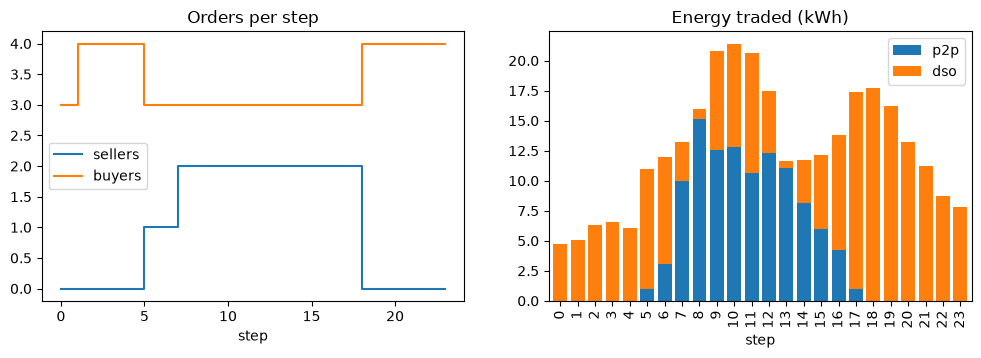

Steps with sellers and buyers: 13 of 24

... of which the best bid reaches the best ask: 13

Peer-to-peer over the day: 107.86 kWh, DSO: 194.76 kWh

In [9]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.5))
day[["sellers", "buyers"]].plot(ax=a, drawstyle="steps-post")
a.set_title("Orders per step")
day[["p2p", "dso"]].plot.bar(ax=b, stacked=True, width=0.8)
b.set_title("Energy traded (kWh)")
plt.show()

both = day[(day.sellers > 0) & (day.buyers > 0)]
crossing = both[both["best bid"] >= both["best ask"]]
print(f"Steps with sellers and buyers: {len(both)} of {len(day)}")
print(f"... of which the best bid reaches the best ask: {len(crossing)}")
print(f"Peer-to-peer over the day: {day.p2p.sum():.2f} kWh, DSO: {day.dso.sum():.2f} kWh")

**Reading it.** Peers can only trade in a step that has both sellers and buyers,
and only when a bid reaches an ask. If the first count is zero the market has
no counterparty, which is a scenario question (who is placed, batteries), not a
clearing bug. If the second is zero the prices never cross: check `bid_margin`
(below 0.5 for overlap) and the price bounds.

## 5. Checks

Rules every step must keep. Each check prints PASS, or FAIL with the first
steps that break it.

In [10]:
TOL = 1e-6


def check_day(scenario: Scenario, records: list[StepRecord]) -> pd.DataFrame:
    fit, utility = scenario.dso.feed_in_tariff, scenario.dso.utility_price
    batteries = {p.id: p.battery for p in scenario.participants}
    failures: dict[str, list[str]] = {}

    def fail(name: str, step: int, text: str) -> None:
        failures.setdefault(name, []).append(f"step {step}: {text}")

    for r in records:
        orders = {o.agent_id: o for o in r.orders}
        # Every order is cleared by the end of stage 3.
        left = r.stages[-1].remaining if r.stages else ()
        if any(o.quantity > TOL for o in left):
            fail("all orders cleared", r.step, f"{len(left)} open")
        for t in r.trades:
            if t.buyer_id == t.seller_id:
                fail("no self-trade", r.step, t.buyer_id)
            dso = DSO_ID in (t.buyer_id, t.seller_id)
            if dso != (t.stage == 3):
                fail("DSO only in stage 3", r.step, f"stage {t.stage}")
            if t.stage == 3:
                want = fit if t.buyer_id == DSO_ID else utility
                if abs(t.price - want) > TOL:
                    fail("DSO pays FiT, charges utility", r.step, f"{t.price}")
            else:
                ask, bid = orders[t.seller_id].price, orders[t.buyer_id].price
                if not ask - TOL <= t.price <= bid + TOL:
                    fail("peer price between ask and bid", r.step,
                         f"{t.price:.4f} not in [{ask:.4f}, {bid:.4f}]")
        # No one trades more than its order, on the order's side.
        for pid, o in orders.items():
            traded = sum(t.quantity for t in r.trades
                         if (t.buyer_id if o.is_buy else t.seller_id) == pid)
            if abs(traded - o.quantity) > TOL:
                fail("traded = order quantity", r.step,
                     f"{pid} traded {traded:.4f} of {o.quantity:.4f}")
        for pid, out in r.participants.items():
            if pid not in orders and (out.bought_kwh or out.sold_kwh):
                fail("no trade without an order", r.step, pid)
            # The battery and the trades cover the participant's net position.
            if abs(out.external_kwh) > TOL:
                fail("nothing left untraded", r.step,
                     f"{pid} external {out.external_kwh:.4f} kWh")
            b = batteries[pid]
            if b and out.soc_kwh is not None and not (
                b.min_soc * b.capacity_kwh - TOL
                <= out.soc_kwh
                <= b.max_soc * b.capacity_kwh + TOL
            ):
                fail("battery inside its window", r.step, f"{pid} {out.soc_kwh:.3f}")
        if not r.grid.converged:
            fail("power flow converges", r.step, "did not converge")

    names = [
        "all orders cleared", "no self-trade", "DSO only in stage 3",
        "DSO pays FiT, charges utility", "peer price between ask and bid",
        "traded = order quantity", "no trade without an order",
        "nothing left untraded", "battery inside its window", "power flow converges",
    ]
    return pd.DataFrame(
        [
            {
                "check": n,
                "result": "FAIL" if n in failures else "PASS",
                "first failures": "; ".join(failures.get(n, [])[:3]),
            }
            for n in names
        ]
    ).set_index("check")


check_day(scenario, records)

,result,first failures
check,,
all orders cleared,PASS,
no self-trade,PASS,
DSO only in stage 3,PASS,
"DSO pays FiT, charges utility",PASS,
peer price between ask and bid,PASS,
traded = order quantity,PASS,
no trade without an order,PASS,
nothing left untraded,PASS,
battery inside its window,PASS,


## 6. Experiments

Change one thing, play the day again, compare. `compare` takes named scenarios
and returns the day's totals and the checks side by side.

In [11]:
from copy import deepcopy


def compare(**scenarios: Scenario) -> pd.DataFrame:
    rows = {}
    for name, s in scenarios.items():
        recs, d = run_day(s)
        checks = check_day(s, recs)
        rows[name] = {
            "participants": len(s.participants),
            "steps with both sides": int(((d.sellers > 0) & (d.buyers > 0)).sum()),
            "p2p kWh": d.p2p.sum(),
            "dso kWh": d.dso.sum(),
            "checks failed": int((checks.result == "FAIL").sum()),
        }
    return pd.DataFrame(rows)


with_loads = deepcopy(scenario)
placement.place_all(with_loads, "loads", battery_kwh=10)

no_batteries = deepcopy(scenario)
for p in no_batteries.participants:
    p.battery = None

high_margin = deepcopy(with_loads)
high_margin.market.bid_margin = 0.6

compare(
    prosumers=scenario,
    every_load_bus=with_loads,
    prosumers_no_battery=no_batteries,
    loads_margin_0_6=high_margin,
)

,prosumers,every_load_bus,prosumers_no_battery,loads_margin_0_6
participants,5.000,13.000,5.000,13.000
steps with both sides,13.000,12.000,13.000,12.000
p2p kWh,107.862,217.426,114.613,66.359
dso kWh,194.761,415.167,199.753,717.300
checks failed,0.000,0.000,0.000,1.000
